# Gradient term: does it work?

The gradient term from `astrometry_corr_gradient/gradient_term.py`, checked on
the matched sources in `gradient_term_calibration_set.ecsv`, which
`gradient_term_calibration.ipynb` makes.

**The plan**

- **History:** each quarter is corrected with its own values.
- **From the 2026 release:** each new quarter uses the previous quarter's
  values. They never change.
- **Both parts follow this rule:** the CALALIGN value and the term's
  reference come from the same quarter.

The check compares the plan with **lagging throughout**: the previous
quarter's values everywhere.

**The CALALIGN values**

- **Before 2021-07-02:** today's CALDB.
- **From 2021-07-02:** the mock N0011 matrices,
  `astrometry_corr_gradient/data/calalign_mock_n0011.ecsv`. One per quarter and
  detector, made the old way: each quarter's median offset, without the term,
  plus one constant per detector. They go through the same matrix code as the
  shipped CALALIGN files.
- **In-sample, like today's CALDB:** a quarter's matrix is made from all of its
  sources, the scored ones included.

**What it shows**

- **The module's numbers** come back exactly from the calibration set.
- **The mock N0011 matrices work.** Before 2021-07-02 nothing changes; after
  it, each quarter's median is at zero, as intended.
- **The term helps in every period.** dr r68 / r90 drops from 0.353" / 0.586"
  to 0.290" / 0.480" before 2021-07-02, and from 0.585" / 0.861" to 0.385" /
  0.621" since.
- **The plan beats lagging throughout since 2021-07-02**, by 0.049" in r68 and
  0.079" in r90. Before 2021-07-02 they tie.
- **The biggest difference is Safe Mode #10, in late 2022.** Lagging spikes
  there; the plan doesn't.

dr is the offset on the sky. r68 and r90 are the radii that hold 68% and 90%
of the sources, in arcsec. For dz and dy alone they are p68 and p90.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from astropy.table import Table, vstack
from astropy.time import Time

# this checkout's package, before any installed copy
sys.path.insert(0, str(Path.cwd().parent))
sys.path.insert(1, str(Path.cwd().parent / "scripts"))
from make_mock_n0011 import MOCK_PATH, build
from update_gradient_term_data import (
    RELEASE_QUARTER,
    handoff_data,
)

from astrometry_corr_gradient import gradient_term
from astrometry_corr_gradient.calalign import (
    calalign_table,
    current_caldb_matrices,
    latest_matrices,
)
from astrometry_corr_gradient.groups import block_bootstrap_difference
from astrometry_corr_gradient.mock_n0011 import (
    detector_constants,
    mock_matrices,
    quarter_levels,
)

AXES = gradient_term.AXES
inputs = Table.read("gradient_term_calibration_set.ecsv", format="ascii.ecsv")
dates = np.asarray(inputs["date"]).astype(str)
years = np.asarray(inputs["year"], float)
assert np.all(np.diff(years) >= 0), "the sources should be in time order"
detectors = np.asarray(inputs["detector"]).astype(str)
offsets = {
    axis_name: np.asarray(inputs[f"{axis_name}_rebased"], float) for axis_name in AXES
}
gradients = {
    name: np.asarray(inputs[name], float) for name in gradient_term.GRADIENT_MSIDS
}
quarters = gradient_term.quarter_index(dates)
export_quarter = int(
    gradient_term.quarter_index(inputs.meta["made"].removesuffix(" UTC"))[0]
)
release_quarter = gradient_term.label_index(RELEASE_QUARTER)
print(
    f"{len(inputs):,} matched sources, {dates[0][:10]} to {dates[-1][:10]},"
    f" made {inputs.meta['made']}; lagging from {RELEASE_QUARTER}"
)

8,827 matched sources, 2004-01-03 to 2026-11-04, made 2026-11-23 02:33 UTC; lagging from 2026Q4


## 1. The module's numbers

Remake the coefficients, sigmas, reference table and test vectors from the
calibration set, `gradient_term_calibration_set.ecsv`. They should match the
module exactly.


In [2]:
coefficients, sigmas, references, vectors = handoff_data(inputs)
assert coefficients == gradient_term.COEFFICIENTS
assert sigmas == gradient_term.SIGMAS
embedded = gradient_term.reference_table()
assert list(embedded["quarter"]) == list(references["quarter"])
assert list(embedded["from_quarter"]) == list(references["from_quarter"])
for name in gradient_term.GRADIENT_MSIDS:
    assert np.allclose(embedded[name], references[name], rtol=0, atol=1e-9)
assert list(gradient_term.vector_table()["obsid"]) == list(vectors["obsid"])
print(
    "the module's coefficients, sigmas, reference table and test vectors match a fresh fit from the calibration set"
)
print("coefficients (arcsec per K):", gradient_term.COEFFICIENTS)
print("sigmas (K):", gradient_term.SIGMAS)

the module's coefficients, sigmas, reference table and test vectors match a fresh fit from the calibration set
coefficients (arcsec per K): {'dz': {'OOBAGRD3': 0.475, 'OOBAGRD6': -13.581}, 'dy': {'OOBAGRD3': 1.559, 'OOBAGRD6': -11.532}}
sigmas (K): {'OOBAGRD3': 0.1117, 'OOBAGRD6': 0.00737}


## 2. The residuals

The offset left after the CALALIGN values, alone and with the term, by period.
A source without telemetry gets no term, as in processing.

"Better" means the difference holds up when the data are resampled in 30-day
blocks; "tie" means it doesn't.


In [3]:
CUTOVER_DATE = "2021-07-02"  # today's last CALALIGN value; mock N0011 from here
shipped = calalign_table()
reference = latest_matrices(shipped)  # what the offsets are rebased onto
times = Time(dates).cxcsec
reference_offsets = {
    axis_name: np.array([reference[detector][axis_name] for detector in detectors])
    for axis_name in AXES
}
last_complete = export_quarter - 1


def after_calalign(mock: Table) -> dict[str, np.ndarray]:
    """The offsets if processed with today's CALDB plus the mock N0011 matrices."""
    current_dy, current_dz = current_caldb_matrices(
        detectors, times, vstack([shipped, mock], metadata_conflicts="silent")
    )
    current = {"dz": current_dz, "dy": current_dy}
    return {
        axis_name: offsets[axis_name]
        + (current[axis_name] - reference_offsets[axis_name])
        for axis_name in AXES
    }


# the plan: the saved mock N0011 (own quarters before the release); lagging throughout: every quarter lags
saved = calalign_table(MOCK_PATH)
fresh = build(inputs)
assert list(saved["start"]) == list(fresh["start"])
assert list(saved["detector"]) == list(fresh["detector"])
for axis_name in AXES:
    assert np.allclose(saved[axis_name], fresh[axis_name], rtol=0, atol=1e-9)
mocks = {
    "within chunk": saved,
    "lagging": mock_matrices(
        inputs, last_complete_quarter=last_complete, lagging_from=int(quarters.min())
    ),
}
calaligns = {scheme: after_calalign(mock) for scheme, mock in mocks.items()}
print(
    f"the saved mock N0011 ({len(saved)} matrices, {saved['start'][0]} to {saved['start'][-1]})"
    " matches a fresh build from the calibration set"
)

# before 2021-07-02 the mock changes nothing: today's CALDB
before = dates < CUTOVER_DATE
for axis_name in AXES:
    today = offsets[axis_name] + np.asarray(inputs[f"{axis_name}_caldb_shift"], float)
    for by_axis in calaligns.values():
        assert np.allclose(
            by_axis[axis_name][before], today[before], rtol=0, atol=1e-9, equal_nan=True
        )
print("before 2021-07-02: today's CALDB, unchanged")

# each quarter's median is at zero once the detector constants are added back;
# the first quarter's also counts its sources from before 2021-07-02, which keep today's CALDB
first_mock_quarter = int(gradient_term.quarter_index(CUTOVER_DATE)[0])
levels = quarter_levels(
    inputs, last_complete, gradient_term.label_index(RELEASE_QUARTER)
)
constants = detector_constants(inputs, levels)
for axis_name in AXES:
    added_back = calaligns["within chunk"][axis_name] + np.array(
        [constants[axis_name][detector] for detector in detectors]
    )
    medians = {
        index: float(
            np.median(added_back[(quarters == index) & np.isfinite(added_back)])
        )
        for index in range(first_mock_quarter, last_complete + 1)
    }
    assert all(
        abs(median) < 1e-9
        for index, median in medians.items()
        if index > first_mock_quarter
    )
    print(
        f"{axis_name}: each quarter's median is 0 from"
        f" {gradient_term.quarter_label(first_mock_quarter + 1)};"
        f" {gradient_term.quarter_label(first_mock_quarter)}'s is"
        f" {medians[first_mock_quarter]:+.3f} arcsec"
    )
early = int(np.sum((quarters == first_mock_quarter) & before))
print(
    f"({gradient_term.quarter_label(first_mock_quarter)} has {early} sources from before"
    " 2021-07-02, which keep today's CALDB)"
)

_, first_rows = np.unique(np.asarray(inputs["obsid"]), return_index=True)
lagging_table = gradient_term.quarter_references(
    quarters[first_rows],
    {name: column[first_rows] for name, column in gradients.items()},
    last_complete_quarter=last_complete,
    lagging_from=int(quarters.min()),
)
for name in gradient_term.GRADIENT_MSIDS:
    lagging_table[name] = np.round(lagging_table[name], 5)
terms = {
    "within chunk": gradient_term.gradient_term(dates, gradients),
    "lagging": gradient_term.gradient_term(
        dates, gradients, lagging_table, gradient_term.COEFFICIENTS
    ),
}
VERSIONS = {}
for scheme in ("within chunk", "lagging"):
    VERSIONS[f"{scheme}: CALALIGN alone"] = calaligns[scheme]
    VERSIONS[f"{scheme}: CALALIGN + term"] = {
        axis_name: calaligns[scheme][axis_name] - terms[scheme][axis_name]
        for axis_name in AXES
    }
for by_axis in VERSIONS.values():
    by_axis["dr"] = np.hypot(by_axis["dz"], by_axis["dy"])
scored = np.logical_and.reduce(
    [np.isfinite(by_axis["dr"]) for by_axis in VERSIONS.values()]
    + [~term["no_reference"] for term in terms.values()]
)
print(
    f"{int(scored.sum()):,} sources, {int((scored & ~terms['within chunk']['no_telemetry']).sum()):,} with the term"
)


def decimal_year(date: str) -> float:
    return float(Time(date).decimalyear)


CUTOVER = decimal_year(CUTOVER_DATE)
WINDOWS = [
    ("mission", -np.inf, np.inf),
    ("before 2021-07-02", -np.inf, CUTOVER),
    (
        "2006-12-10 to 2012-09-13",
        decimal_year("2006-12-10"),
        decimal_year("2012-09-13"),
    ),
    ("2013-01-19 to 2021-07-02", decimal_year("2013-01-19"), CUTOVER),
    ("since 2021-07-02", CUTOVER, np.inf),
    ("2023+", 2023.0, np.inf),
]


def score_rows(axis_names: tuple[str, ...], names: list[str]) -> Table:
    rows = []
    for axis_name in axis_names:
        for name in names:
            row = {"offset": axis_name, "correction": name}
            for window, low, high in WINDOWS:
                chosen = np.abs(
                    VERSIONS[name][axis_name][scored & (years >= low) & (years < high)]
                )
                row[window] = (
                    f"{np.percentile(chosen, 68):.3f} / {np.percentile(chosen, 90):.3f}"
                )
            rows.append(row)
    return Table(rows=rows)


print("dr: 68% / 90% of |offset| (arcsec)")
score_rows(("dr",), list(VERSIONS)).pprint(max_width=-1)
print()
print("dz and dy, within chunk: 68% / 90% of |offset| (arcsec)")
score_rows(
    ("dz", "dy"), ["within chunk: CALALIGN alone", "within chunk: CALALIGN + term"]
).pprint(max_width=-1)
print()


def versus(name: str, reference: str) -> None:
    print(f"dr, {name} minus {reference}, paired 30-day-block bootstraps")
    for window, low, high in WINDOWS:
        both = scored & (years < high)
        verdicts = []
        for statistic, q in (("r68", 68), ("r90", 90)):
            difference, lower, upper = block_bootstrap_difference(
                np.where(both, VERSIONS[name]["dr"], np.nan),
                np.where(both, VERSIONS[reference]["dr"], np.nan),
                years,
                lambda chosen, q=q: np.percentile(np.abs(chosen), q),
                year_min=low,
            )
            verdict = "better" if upper < 0 else ("worse" if lower > 0 else "tie")
            verdicts.append(f"{statistic} {difference:+.3f} {verdict}")
        print(f"    {window}: " + "; ".join(verdicts))


versus("within chunk: CALALIGN + term", "within chunk: CALALIGN alone")
versus("within chunk: CALALIGN + term", "lagging: CALALIGN + term")

the saved mock N0011 (88 matrices, 2021-07-02 to 2026-10-01) matches a fresh build from the calibration set
before 2021-07-02: today's CALDB, unchanged
dz: each quarter's median is 0 from 2021Q4; 2021Q3's is +0.005 arcsec
dy: each quarter's median is 0 from 2021Q4; 2021Q3's is +0.000 arcsec
(2021Q3 has 2 sources from before 2021-07-02, which keep today's CALDB)
8,758 sources, 8,745 with the term
dr: 68% / 90% of |offset| (arcsec)
offset           correction             mission    before 2021-07-02 2006-12-10 to 2012-09-13 2013-01-19 to 2021-07-02 since 2021-07-02     2023+    
------ ----------------------------- ------------- ----------------- ------------------------ ------------------------ ---------------- -------------
    dr  within chunk: CALALIGN alone 0.426 / 0.697     0.353 / 0.586            0.267 / 0.442            0.437 / 0.667    0.585 / 0.861 0.599 / 0.887
    dr within chunk: CALALIGN + term 0.320 / 0.526     0.290 / 0.480            0.237 / 0.392            0.342 / 0.5

    mission: r68 -0.106 better; r90 -0.171 better


    before 2021-07-02: r68 -0.063 better; r90 -0.105 better


    2006-12-10 to 2012-09-13: r68 -0.030 better; r90 -0.050 better


    2013-01-19 to 2021-07-02: r68 -0.095 better; r90 -0.139 better


    since 2021-07-02: r68 -0.200 better; r90 -0.241 better


... (3 outputs left out)

    2006-12-10 to 2012-09-13: r68 -0.008 better; r90 -0.005 tie


    2013-01-19 to 2021-07-02: r68 -0.007 tie; r90 +0.004 tie


    since 2021-07-02: r68 -0.049 better; r90 -0.079 better


    2023+: r68 -0.037 better; r90 -0.042 tie


## 3. Over time

dr r68 and r90 in 90-day windows.


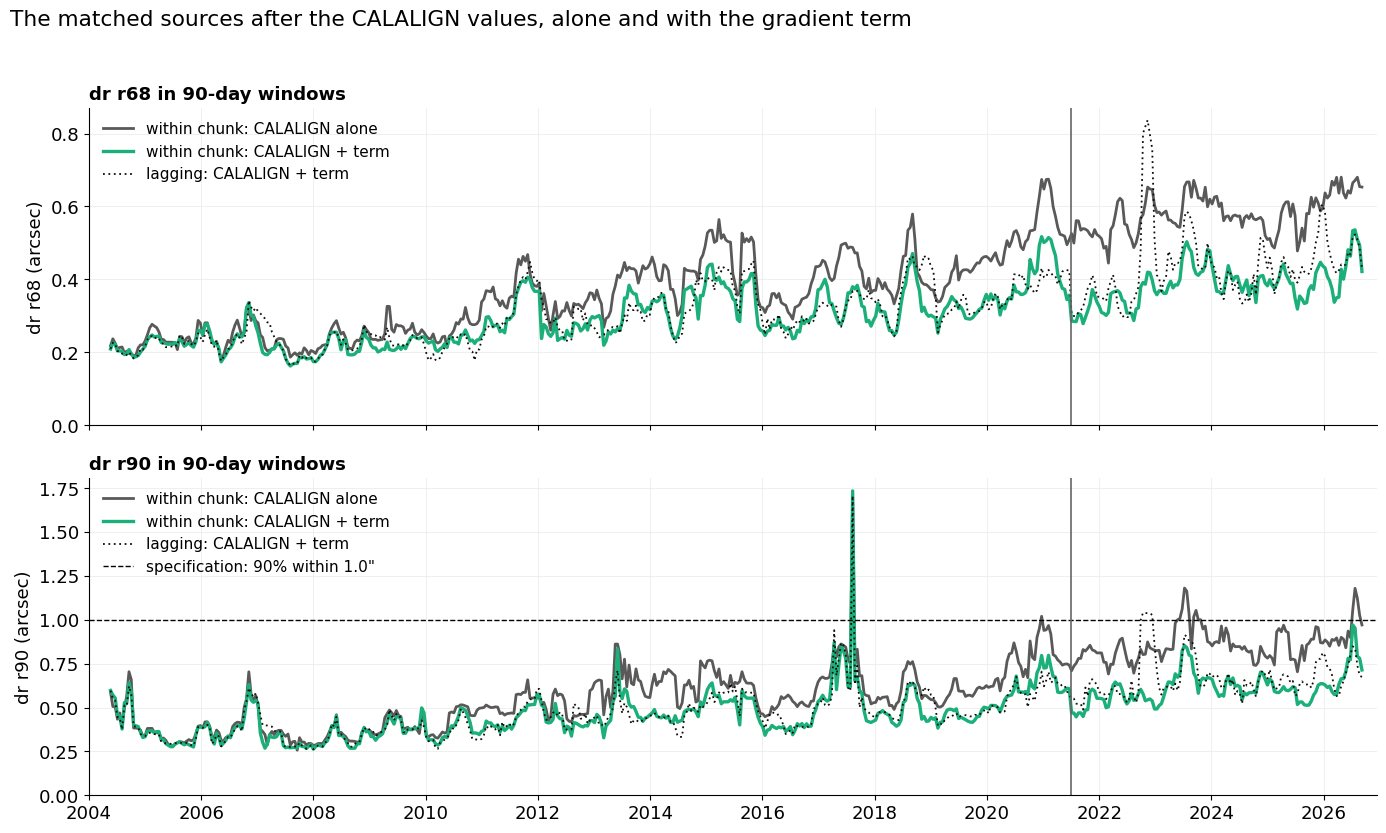

In [4]:
HALF_WINDOW, STEP = 45 / 365.25, 15 / 365.25
centers = np.arange(years[scored].min() + HALF_WINDOW, years.max() - HALF_WINDOW, STEP)


def running(values: np.ndarray, q: float) -> np.ndarray:
    out = np.full(len(centers), np.nan)
    for index, center in enumerate(centers):
        side = (years < CUTOVER) if center < CUTOVER else (years >= CUTOVER)
        near = scored & side & (np.abs(years - center) < HALF_WINDOW)
        if near.sum() >= 20:
            out[index] = np.percentile(values[near], q)
    return out


STYLES = {
    "within chunk: CALALIGN alone": ("0.35", 2.0, "-"),
    "within chunk: CALALIGN + term": ("#1baf7a", 2.4, "-"),
    "lagging: CALALIGN + term": ("0.05", 1.3, (0, (1, 2))),
}
plt.rcParams.update({"font.size": 13})
figure, axes = plt.subplots(2, 1, figsize=(14, 8.5), sharex=True)
for axis, (statistic, q) in zip(axes, (("r68", 68), ("r90", 90)), strict=True):
    for name, (color, width, style) in STYLES.items():
        axis.plot(
            centers,
            running(VERSIONS[name]["dr"], q),
            color=color,
            linewidth=width,
            linestyle=style,
            label=name,
        )
    if statistic == "r90":
        axis.axhline(
            1.0,
            color="black",
            linewidth=1.0,
            linestyle="--",
            label='specification: 90% within 1.0"',
        )
    axis.axvline(CUTOVER, color="0.4", linewidth=1.2)
    axis.set_ylim(bottom=0)
    axis.set_ylabel(f"dr {statistic} (arcsec)")
    axis.set_title(
        f"dr {statistic} in 90-day windows", loc="left", fontsize=13, fontweight="bold"
    )
    axis.grid(color="0.93", linewidth=0.6)
    for side in ("top", "right"):
        axis.spines[side].set_visible(False)
    axis.legend(loc="upper left", fontsize=11, frameon=False)
axes[-1].set_xlim(2004.0, years.max() + 0.1)
axes[-1].set_xticks(range(2004, 2027, 2), [str(year) for year in range(2004, 2027, 2)])
figure.suptitle(
    "The matched sources after the CALALIGN values, alone and with the gradient term",
    x=0.01,
    ha="left",
)
figure.tight_layout(rect=(0, 0, 1, 0.96))
figure.savefig("gradient_term_validation.png", dpi=150)
plt.show()

## Notes

- **In-sample:** the coefficients were fit on these same sources, and the mock
  N0011 matrices were made from them.
- **Leaving each source out of its own quarter's median** (the old stand-in
  did this, with the sources linked to it) puts the plan since 2021-07-02 at
  0.401" / 0.645" with the term: 0.016" / 0.024" higher. Lagging doesn't
  change. The plan then beats lagging by 0.032" in r68; r90 is a tie.
- **2026Q4** was still filling at the export, so it lags in both schemes.
- **The 2017-09 spike** is five M30 sources about 2.5" off, with or without
  the term.
